In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv


# Credit Card Fraud Detection – Muthoot Prep

## Step 1: Problem Statement
- **Problem type (of the 6):** Fraud – credit card transaction fraud detection
- **JD link:** Matches "Risk or fraud-related analytics" (ML use cases) and names XGBoost. JD-based.
- **Business problem:** Rank credit-card transactions so the fraud team can catch as many frauds as possible without flooding analysts with false alerts.
- **Who uses it:** The fraud operations / transaction-monitoring team, at the point a transaction is authorised or shortly after.
- **Target:** `Class = 1` means the transaction was fraudulent; `Class = 0` means it was genuine.
- **Learning type:** Supervised binary classification for logistic regression and XGBoost (the model outputs a fraud probability, and the business chooses a cut-off). Isolation Forest is an unsupervised anomaly-detection comparison, useful when labels are late or incomplete.

**Interview line**
- "I framed this as a supervised binary classification problem: predict the probability that a card transaction is fraud, and I also compared an unsupervised Isolation Forest because fraud labels often arrive late." 

## Roadmap
**What we do**
- Follow 10 steps from the business problem to a saved, tracked model.

**Flow:** Problem → Load → Imbalance → EDA → Split and scale → Logistic baseline → XGBoost → Isolation Forest → Evaluate → SHAP → MLflow

**Libraries flow:** Problem → Load (pandas) → Imbalance (pandas) → EDA (pandas, matplotlib, scipy Mann-Whitney) → Split and scale (scikit-learn train_test_split, StandardScaler) → Logistic baseline (scikit-learn LogisticRegression) → XGBoost (xgboost) → Isolation Forest (scikit-learn IsolationForest) → Evaluate (scikit-learn metrics, matplotlib) → SHAP (shap) → MLflow (mlflow, joblib)

**Steps**
- Step 1: Problem statement, load the data and inspect it
- Step 2: Class imbalance
- Step 3: EDA on Amount and Time, with a Mann-Whitney test
- Step 4: Stratified train / validation / test split, then scale Amount and Time
- Step 5: Baseline logistic regression with class_weight
- Step 6: XGBoost (main model) with scale_pos_weight and early stopping on aucpr
- Step 7: Isolation Forest as an unsupervised comparison
- Step 8: Evaluation for imbalance: PR-AUC, ROC-AUC, cost-based cut-off and precision@k
- Step 9: Feature importance and SHAP
- Step 10: MLflow tracking and saving the model with joblib

**Why it matters**
- Shows the full ML lifecycle in order, which is what the JD asks for (JD-based).
- Easy to walk an interviewer through, one step at a time.

## Glossary
- **Fraud:** a payment the real cardholder did not authorise. Here `Class = 1` marks a fraudulent transaction.
- **Chargeback:** the cardholder disputes a charge and the issuer may have to repay it. That loss is a common reason fraud labels arrive days or weeks late.
- **False alert (false positive):** a genuine transaction the model flags. It costs analyst time and can annoy a real customer.
- **Missed fraud (false negative):** a fraud the model lets through. It costs the transaction amount and often a chargeback.
- **Class imbalance:** one class is much rarer than the other (about 0.17% fraud here), so accuracy and even ROC-AUC can look too good.
- **PCA (Principal Component Analysis):** a transform that turns original features into uncorrelated components. `V1` to `V28` are PCA components, so we cannot read them as "merchant" or "country".
- **Precision:** of the transactions we flagged, the share that were really fraud.
- **Recall:** of all frauds, the share we flagged.
- **F1:** the balance between precision and recall (their harmonic mean).
- **PR-AUC (Average Precision):** area under the precision-recall curve. The main metric when fraud is rare. A random model scores close to the fraud rate.
- **ROC-AUC:** the chance the model scores a random fraud above a random genuine transaction. Still useful, but it can look optimistic when negatives vastly outnumber positives.
- **Precision@k:** of the k highest-scored transactions (the review queue), the share that were fraud.
- **class_weight / scale_pos_weight:** tells the model to pay more attention to the rare fraud class.
- **Early stopping:** stop adding trees when the validation metric stops improving, to avoid overfitting.
- **Isolation Forest:** an unsupervised model that flags unusual points as anomalies. It does not need fraud labels to train.
- **Threshold (cut-off):** the score above which we raise an alert.
- **Mann-Whitney U test:** a test of whether two groups have different distributions, without assuming a bell-shaped curve. Better than a t-test when Amount is skewed.
- **p-value:** the chance of seeing a difference this big if there were really no difference. Below 0.05 we call it significant.
- **StandardScaler:** puts a column on a mean-0, standard-deviation-1 scale so large-range features do not dominate.
- **SHAP:** explains each prediction by showing how much each feature pushed the fraud score up or down.
- **MLflow:** a tool that logs parameters, metrics and models so experiments can be compared and reproduced.

### Load data and inspect it
**What we do**
- Load the transaction table (one row per card transaction).
- Check rows, columns, data types, missing values and exact duplicate rows.
- Drop exact duplicate rows, then check the fraud count.

**Why it matters**
- Confirms the file loaded correctly and that we know the path.
- Missing values and duplicates are the first data-quality checks. Duplicate rows would give the model the same transaction twice.
- The fraud count tells us how rare the event is, which drives the choice of metrics later.

**Domain link**
- Each row is one card payment. `Class` is a confirmed fraud label, often known only after a customer dispute or a chargeback, so in live traffic the label can lag the transaction by days or weeks.
- JD-based: "data collection" and "data preparation" in the ML lifecycle. Domain-based: card transaction monitoring.

**Interview line**
- "First I loaded the file, checked there were no missing values, dropped a small number of exact duplicate rows, and confirmed fraud is well under 1% of transactions." 

In [2]:
path = '/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv'
df = pd.read_csv(path)

print(f"Rows     : {df.shape[0]:,}")
print(f"Columns  : {df.shape[1]}")
print(f"Column names: {list(df.columns)}")
print("\nData types:")
print(df.dtypes.value_counts())
print("\nFirst 5 rows:")
print(df.head())

print(f"\nMissing values : {df.isna().sum().sum():,}")
print(f"Duplicate rows : {df.duplicated().sum():,}")

# Exact copies of the same transaction add no new information, so we drop them
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows after dropping duplicates: {len(df):,} (removed {n_before - len(df):,})")

print("\nClass counts (0 = genuine, 1 = fraud):")
print(df['Class'].value_counts())
print(f"Fraud rate: {df['Class'].mean():.4%}")

Rows     : 284,807
Columns  : 31
Column names: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
float64    30
int64       1
Name: count, dtype: int64

First 5 rows:
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.0851

Duplicate rows : 1,081


Rows after dropping duplicates: 283,726 (removed 1,081)

Class counts (0 = genuine, 1 = fraud):
Class
0    283253
1       473
Name: count, dtype: int64
Fraud rate: 0.1667%


**Findings**
- The file has 284,807 rows and 31 columns (Time, V1 to V28, Amount, Class). After dropping 1,081 exact duplicate rows there are 283,726 rows.
- There are no missing values.
- 283,253 genuine transactions and 473 frauds, a fraud rate of 0.1667%.
- **How to read this:** a fraud rate well below 1% means accuracy will look excellent if the model always predicts "genuine". We use PR-AUC, precision and recall instead.

## Step 2: Class Imbalance
**What we do**
- Count genuine vs fraud transactions and the imbalance ratio (how many genuine payments per fraud).
- Plot a simple bar chart of the two classes.

**Why it matters**
- This is an extreme imbalance problem. A useless model that never flags fraud would still be more than 99% accurate.
- The imbalance ratio is also the starting value for `scale_pos_weight` in XGBoost.
- Seeing the bar chart makes the rarity of fraud obvious before we talk about metrics.

**Domain link**
- Real card fraud is rare, but each miss can be a full chargeback. Fraud teams therefore care more about catching fraud and keeping the alert queue reviewable than about overall accuracy.
- JD-based: "fraud-related analytics". Domain-based: rare-event detection in transaction monitoring.

**Interview line**
- "Fraud is only about 0.17% of transactions, so I treated this as a rare-event problem and judged models on PR-AUC, not accuracy." 

Genuine transactions : 283,253
Fraud transactions   : 473
Fraud rate           : 0.1667%
Imbalance ratio      : 598.8 genuine transactions for every fraud


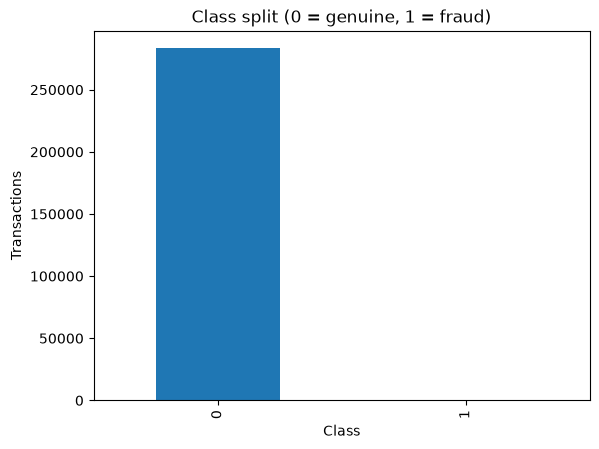

In [3]:
import matplotlib.pyplot as plt

counts = df['Class'].value_counts().sort_index()
n_genuine = counts[0]
n_fraud = counts[1]
ratio = n_genuine / n_fraud

print(f"Genuine transactions : {n_genuine:,}")
print(f"Fraud transactions   : {n_fraud:,}")
print(f"Fraud rate           : {n_fraud / len(df):.4%}")
print(f"Imbalance ratio      : {ratio:.1f} genuine transactions for every fraud")

counts.plot(kind='bar', title='Class split (0 = genuine, 1 = fraud)')
plt.ylabel('Transactions')
plt.show()

**Findings**
- 283,253 genuine vs 473 fraud (0.1667%), or 598.8 genuine transactions for every fraud.
- A model that never flags fraud would still be 99.83% accurate, so we judge the model on PR-AUC, precision and recall, not accuracy.
- **How to read this:** if one bar is much taller than the other, accuracy will mislead. The random-model PR-AUC later should sit near this fraud rate (0.1667%, or 0.0017 as a decimal).

## Step 3: Exploratory Data Analysis (EDA)
**What we do**
- Compare `Amount` for fraud vs genuine transactions (mean and median).
- Test whether `Amount` differs between the two classes with a Mann-Whitney U test, and show a Welch t-test as a comparison.
- Plot the distribution of `Amount` (on a log scale, because it is skewed) and of `Time` (in hours from the first transaction).
- Rank features by the absolute correlation with `Class`.

**Why it matters**
- EDA tells us whether amount and timing even differ for fraud, and which of the PCA features carry the most linear signal.
- `Amount` is skewed (a long tail of large payments), so the mean and the median can tell different stories, and Mann-Whitney is safer than a t-test.
- p-value < 0.05 means the difference is unlikely to be random. With hundreds of thousands of rows, even a small difference can be "significant", so we also look at the size of the gap.

**Stats used:** Mann-Whitney U test, Welch's t-test, Pearson correlation.

**Domain link**
- Fraud is not only large purchases. Stolen cards are often "tested" with a small payment first, then used for a larger one. A lower median and a higher mean can appear together when both patterns exist.
- `Time` in this file is seconds since the first transaction, covering about two days. In a bank you would instead use hour of day, weekend flags and time since the last payment on the same card.
- JD-based: "exploratory analysis" and "statistical analysis". Domain-based: card-testing vs high-value fraud.

**Interview line**
- "Amount is skewed, so I compared medians as well as means and used a Mann-Whitney test rather than relying only on a t-test." 

Amount by class:
  Genuine  mean = 88.41 | median = 22.00
  Fraud    mean = 123.87 | median = 9.82

Mann-Whitney U on Amount : U = 59,517,130 | p-value = 2.686e-05
Welch t-test on Amount    : t = 2.96 | p-value = 0.003217


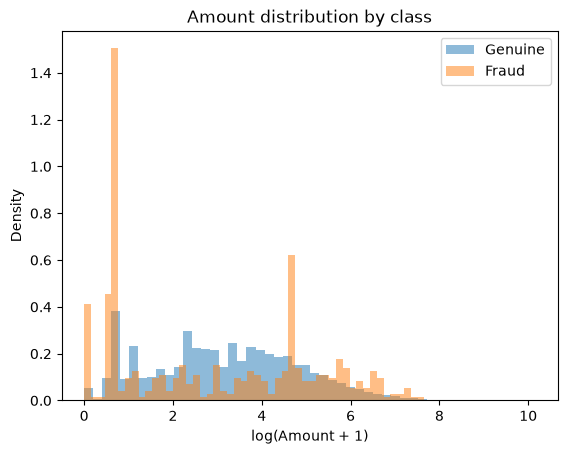

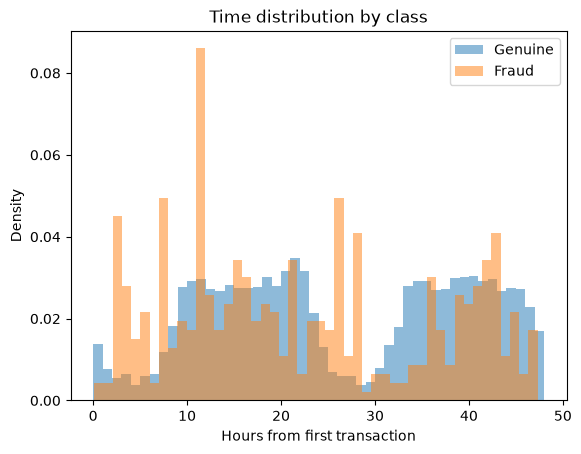


Top 10 features by |correlation| with Class:
V17    0.313
V14    0.293
V12    0.251
V10    0.207
V16    0.187
V3     0.182
V7     0.172
V11    0.149
V4     0.129
V18    0.105
dtype: float64


In [4]:
from scipy import stats

fraud = df[df['Class'] == 1]
genuine = df[df['Class'] == 0]

print("Amount by class:")
print(f"  Genuine  mean = {genuine['Amount'].mean():.2f} | median = {genuine['Amount'].median():.2f}")
print(f"  Fraud    mean = {fraud['Amount'].mean():.2f} | median = {fraud['Amount'].median():.2f}")

# Amount is skewed (mean is pulled by large payments), so Mann-Whitney is the main test
u_stat, p_mw = stats.mannwhitneyu(fraud['Amount'], genuine['Amount'], alternative='two-sided')
t_stat, p_t = stats.ttest_ind(fraud['Amount'], genuine['Amount'], equal_var=False)
print(f"\nMann-Whitney U on Amount : U = {u_stat:,.0f} | p-value = {p_mw:.4g}")
print(f"Welch t-test on Amount    : t = {t_stat:.2f} | p-value = {p_t:.4g}")

# log(Amount + 1) so the long tail does not squash the chart
for label, grp in [('Genuine', genuine), ('Fraud', fraud)]:
    plt.hist(np.log1p(grp['Amount']), bins=50, alpha=0.5, density=True, label=label)
plt.xlabel('log(Amount + 1)')
plt.ylabel('Density')
plt.title('Amount distribution by class')
plt.legend()
plt.show()

# Time is seconds from the first transaction in this file (about two days)
for label, grp in [('Genuine', genuine), ('Fraud', fraud)]:
    plt.hist(grp['Time'] / 3600, bins=48, alpha=0.5, density=True, label=label)
plt.xlabel('Hours from first transaction')
plt.ylabel('Density')
plt.title('Time distribution by class')
plt.legend()
plt.show()

corr = df.drop(columns=['Class']).corrwith(df['Class']).abs().sort_values(ascending=False)
print("\nTop 10 features by |correlation| with Class:")
print(corr.head(10).round(3))

**Findings**
- Genuine Amount: mean 88.41, median 22.00. Fraud Amount: mean 123.87, median 9.82.
- The mean and the median tell different stories: many frauds are small (lower median, typical of card testing) while a few large ones pull the mean up.
- Both tests find a real difference (Mann-Whitney p = 2.686e-05, Welch t-test p = 0.003217). Amount is skewed, so Mann-Whitney is the test to trust.
- The Time chart only covers about two days of this file, so it is a short window, not a stable daily pattern we could use in production.
- Top |correlation| with Class: V17 0.313, V14 0.293, V12 0.251, V10 0.207 and V16 0.187. The strongest linear signals are PCA components, not Amount or Time.

## Step 4: Train / Validation / Test Split and Scaling
**What we do**
- Split the data in two stages, both stratified on `Class`: first hold out 20% as a test set, then split the remainder into train (60% of all rows) and validation (20% of all rows).
- Fit `StandardScaler` on `Time` and `Amount` using the training set only, then transform validation and test with the same scaler.
- Leave `V1` to `V28` as they are.

**Why it matters**
- A stratified split keeps the fraud rate the same in train, validation and test, which keeps evaluation honest.
- We fit nothing on the test set. The validation set is used later for early stopping and to pick a cut-off. The test set is the final, unseen score.
- `V1` to `V28` are already PCA components on a similar scale. `Time` and `Amount` are not, and would dominate logistic regression and Isolation Forest if left raw.
- Fitting the scaler on all data, or on test, would leak information. Train-only fitting is the correct habit.

**Domain link**
- In production you would scale with the training statistics stored alongside the model, then apply the same transform to each new transaction.
- JD-based: "model development and validation" in the ML lifecycle.

**Interview line**
- "I used a stratified 60/20/20 split so the rare fraud rate is preserved, and I fitted the scaler for Time and Amount on the training set only to avoid leakage." 

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['Class'])
y = df['Class']

# 20% test first, then 25% of the remainder as validation, so the split is 60 / 20 / 20
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

X_train = X_train.copy()
X_valid = X_valid.copy()
X_test = X_test.copy()

# Scale only Time and Amount; V1 to V28 are already PCA features
scaler = StandardScaler()
scale_cols = ['Time', 'Amount']
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_valid[scale_cols] = scaler.transform(X_valid[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

print("Split sizes and fraud counts:")
for name, yy in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]:
    print(f"  {name:12s} rows = {len(yy):,} | frauds = {yy.sum():,} | fraud rate = {yy.mean():.4%}")

print(f"\nFeatures used: {X_train.shape[1]} (Time, V1 to V28, Amount)")
print("Time and Amount were scaled with training-set mean and standard deviation only.")

Split sizes and fraud counts:
  Train        rows = 170,235 | frauds = 284 | fraud rate = 0.1668%
  Validation   rows = 56,745 | frauds = 94 | fraud rate = 0.1657%
  Test         rows = 56,746 | frauds = 95 | fraud rate = 0.1674%

Features used: 30 (Time, V1 to V28, Amount)
Time and Amount were scaled with training-set mean and standard deviation only.


**Findings**
- Train: 170,235 rows and 284 frauds (0.1668%). Validation: 56,745 rows and 94 frauds (0.1657%). Test: 56,746 rows and 95 frauds (0.1674%).
- The fraud rate is almost the same in all three splits, so the stratified split worked.
- Time and Amount were scaled with training statistics only; V1 to V28 were left as they are.

## Step 5: Baseline Model – Logistic Regression
**What we do**
- Train a logistic regression with `class_weight='balanced'`, so the rare fraud class is not ignored.
- Score the test set and report PR-AUC (average precision) and ROC-AUC.
- Show the 10 largest coefficients as a simple explanation of the linear model.

**Why it matters**
- Logistic regression is a clear, explainable baseline. Every stronger model has to beat it.
- `class_weight='balanced'` re-weights the loss so fraud and genuine rows contribute more equally, which is the linear-model version of `scale_pos_weight`.
- PR-AUC is the headline metric. A random model would score close to the test fraud rate. ROC-AUC is reported too, but it can look optimistic on rare events.

**Stats used:** logistic regression coefficients, PR-AUC (average precision), ROC-AUC.

**Domain link**
- A linear model is easy to take to a fraud-risk committee: a positive coefficient raises the log-odds of fraud. It will miss interactions (for example amount combined with an unusual V-pattern), which is why we add a tree model next.
- JD-based: "statistical modelling" and "model evaluation". Domain-based: an explainable fraud baseline.

**Interview line**
- "I started with a class-weighted logistic regression as an explainable baseline and reported PR-AUC against the fraud-rate random baseline, not just ROC-AUC." 

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

log_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)

log_valid_pred = log_model.predict_proba(X_valid)[:, 1]
log_test_pred = log_model.predict_proba(X_test)[:, 1]

log_pr = average_precision_score(y_test, log_test_pred)
log_auc = roc_auc_score(y_test, log_test_pred)
print(f"Random baseline PR-AUC (test fraud rate): {y_test.mean():.4f}")
print(f"Logistic Regression - PR-AUC: {log_pr:.4f} | ROC-AUC: {log_auc:.4f}")

# Largest coefficients (features are on a comparable scale after Step 4)
coefs = pd.Series(log_model.coef_[0], index=X_train.columns)
top10 = coefs.abs().sort_values(ascending=False).head(10).index
print("\nTop 10 logistic coefficients (positive raises the fraud score):")
for f in top10:
    print(f"  {f:10s} coef = {coefs[f]:7.3f}")

Random baseline PR-AUC (test fraud rate): 0.0017
Logistic Regression - PR-AUC: 0.6918 | ROC-AUC: 0.9645

Top 10 logistic coefficients (positive raises the fraud score):
  Amount     coef =   2.392
  V14        coef =  -1.660
  V20        coef =  -1.325
  V10        coef =  -1.197
  V12        coef =  -1.193
  V27        coef =  -1.017
  V17        coef =  -0.979
  V1         coef =   0.937
  V5         coef =   0.866
  V4         coef =   0.850


**Findings**
- Logistic regression baseline: PR-AUC 0.6918 and ROC-AUC 0.9645 on the test set.
- A random model would score about 0.0017 on PR-AUC (the test fraud rate). The baseline is far above that, so the linear model already has real signal. ROC-AUC looks very high, which is typical when genuine transactions vastly outnumber frauds.
- Largest risk-raising coefficient: Amount +2.392 (per 1 standard deviation). Largest risk-lowering coefficients: V14 -1.660, V20 -1.325, V10 -1.197 and V12 -1.193.

## Step 6: XGBoost Model (main model)
**What we do**
- Train an XGBoost classifier, the main model for this project.
- Handle class imbalance with `scale_pos_weight` = number of genuine / number of fraud in the training set.
- Use early stopping on validation `aucpr` (PR-AUC): stop adding trees when that metric has not improved for 50 rounds.
- Compare PR-AUC and ROC-AUC with the logistic regression baseline on the same test set, and plot both PR and ROC curves.

**Why it matters**
- Boosted trees capture non-linear patterns and feature interactions, and usually beat logistic regression on tabular data.
- Without imbalance handling, the model can mostly predict "genuine" and still look accurate.
- Early stopping prevents overfitting and saves time. We monitor `aucpr` because that is the metric that matches a rare-event problem.
- Note: `scale_pos_weight` keeps the ranking (PR-AUC, ROC-AUC) good but pushes probabilities up, so they are not true fraud probabilities. Calibrate them before using them as actual probabilities.
- Note: early stopping uses the validation set. The test set is still held out, so the test score is the honest one.

**Domain link**
- XGBoost is a common production choice for card-fraud ranking because it is strong on tabular data and scores quickly enough for a large transaction stream.
- JD-based: the JD names XGBoost, and this step is "machine learning algorithms (boosting)" and "model development".

**Interview line**
- "XGBoost is the main model: I set scale_pos_weight to the genuine-to-fraud ratio, used early stopping on validation aucpr, and compared PR-AUC with the logistic baseline on a held-out test set." 

scale_pos_weight = 598.42



Best number of trees: 69
Logistic Regression - PR-AUC: 0.6918 | ROC-AUC: 0.9645
XGBoost             - PR-AUC: 0.7507 | ROC-AUC: 0.9674
PR-AUC improvement  : +0.0589


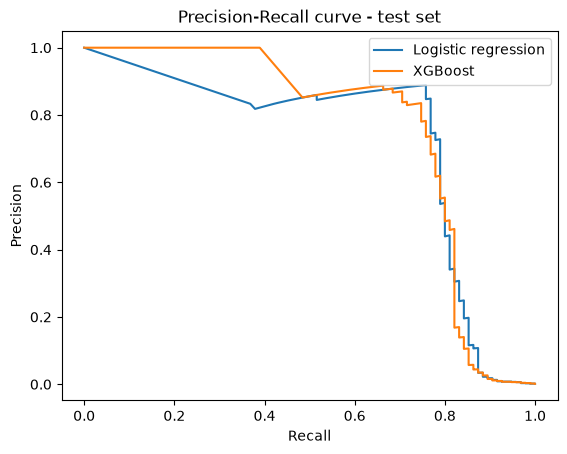

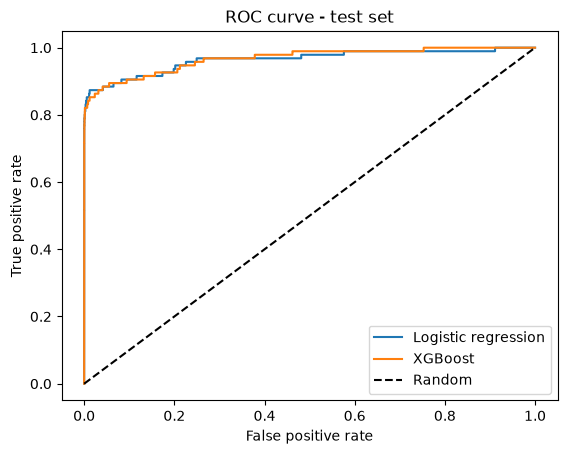

In [7]:
import xgboost as xgb
from sklearn.metrics import precision_recall_curve, roc_curve

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()    # genuine per fraud
print(f"scale_pos_weight = {pos_weight:.2f}")

xgb_model = xgb.XGBClassifier(
    n_estimators=400,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=pos_weight,
    eval_metric='aucpr',
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)

xgb_valid_pred = xgb_model.predict_proba(X_valid)[:, 1]
xgb_test_pred = xgb_model.predict_proba(X_test)[:, 1]

xgb_pr = average_precision_score(y_test, xgb_test_pred)
xgb_auc = roc_auc_score(y_test, xgb_test_pred)

print(f"\nBest number of trees: {xgb_model.best_iteration}")
print(f"Logistic Regression - PR-AUC: {log_pr:.4f} | ROC-AUC: {log_auc:.4f}")
print(f"XGBoost             - PR-AUC: {xgb_pr:.4f} | ROC-AUC: {xgb_auc:.4f}")
print(f"PR-AUC improvement  : {xgb_pr - log_pr:+.4f}")

# PR curve is the main plot; ROC is shown as well
plt.figure()
for name, pred in [('Logistic regression', log_test_pred), ('XGBoost', xgb_test_pred)]:
    prec, rec, _ = precision_recall_curve(y_test, pred)
    plt.plot(rec, prec, label=name)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve - test set')
plt.legend()
plt.show()

plt.figure()
for name, pred in [('Logistic regression', log_test_pred), ('XGBoost', xgb_test_pred)]:
    fpr, tpr, _ = roc_curve(y_test, pred)
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curve - test set')
plt.legend()
plt.show()

**Findings**
- scale_pos_weight was 598.42, and early stopping chose 69 trees.
- XGBoost: PR-AUC 0.7507 and ROC-AUC 0.9674 on the test set.
- PR-AUC improved by +0.0589 over logistic regression (0.6918 to 0.7507). The ROC-AUC gain is tiny (0.9645 to 0.9674), which is why PR-AUC is the number to quote first. The PR-AUC gain is real but moderate; it is worth it if SHAP is used for explanations.
- **How to read this:** the PR curve should stay higher than the logistic curve. The ROC curve looks strong for both models; that is why PR-AUC is the number we quote first.

## Step 7: Isolation Forest (unsupervised comparison)
**What we do**
- Train an Isolation Forest on genuine training transactions only (no fraud labels used in training).
- Set `contamination` to the training fraud rate, as a simple guess of how often anomalies should appear.
- Turn the anomaly score into "higher means more suspicious" and report PR-AUC and ROC-AUC on the same test set.
- Add Isolation Forest to the PR curve.

**Why it matters**
- Isolation Forest is unsupervised: it looks for points that are easy to isolate from the rest, not for a labelled fraud pattern.
- This is the realistic fallback when fraud labels are late, incomplete or unavailable. If the labelled XGBoost model is much stronger, that tells us the labels are carrying real signal.
- We still evaluate it with the labels on the test set, so the comparison is fair.

**Domain link**
- Chargebacks and confirmed fraud cases can arrive days or weeks after the payment. An anomaly model can still raise a review flag in that window, or on new fraud types the labelled model has not seen.
- JD-based: "machine learning algorithms" and anomaly detection as a complement to supervised fraud models. Domain-based: unsupervised transaction monitoring.

**Interview line**
- "I trained Isolation Forest only on genuine transactions as an unsupervised comparison, then scored it on the same test set. It is the model I would lean on if labels were delayed, not a replacement for XGBoost when labels are good." 

Isolation Forest    - PR-AUC: 0.0908 | ROC-AUC: 0.9429
Logistic Regression - PR-AUC: 0.6918 | ROC-AUC: 0.9645
XGBoost             - PR-AUC: 0.7507 | ROC-AUC: 0.9674


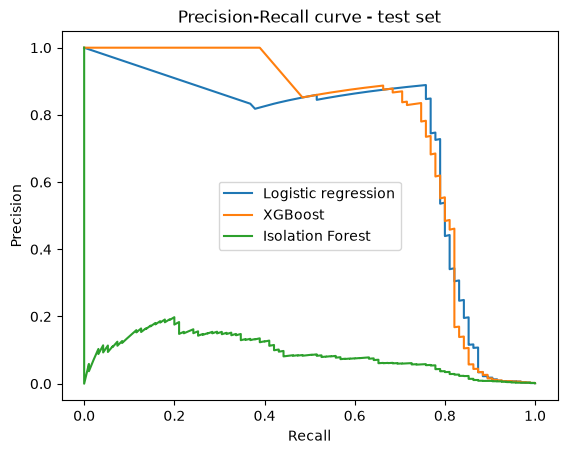

In [8]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(
    n_estimators=100,
    contamination=float(y_train.mean()),    # expected fraud rate
    random_state=42,
    n_jobs=-1,
)
iso.fit(X_train[y_train == 0])              # genuine transactions only

# decision_function is higher for more normal points, so we flip the sign
iso_valid_score = -iso.decision_function(X_valid)
iso_test_score = -iso.decision_function(X_test)

iso_pr = average_precision_score(y_test, iso_test_score)
iso_auc = roc_auc_score(y_test, iso_test_score)
print(f"Isolation Forest    - PR-AUC: {iso_pr:.4f} | ROC-AUC: {iso_auc:.4f}")
print(f"Logistic Regression - PR-AUC: {log_pr:.4f} | ROC-AUC: {log_auc:.4f}")
print(f"XGBoost             - PR-AUC: {xgb_pr:.4f} | ROC-AUC: {xgb_auc:.4f}")

plt.figure()
for name, pred in [('Logistic regression', log_test_pred),
                   ('XGBoost', xgb_test_pred),
                   ('Isolation Forest', iso_test_score)]:
    prec, rec, _ = precision_recall_curve(y_test, pred)
    plt.plot(rec, prec, label=name)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall curve - test set')
plt.legend()
plt.show()

**Findings**
- Isolation Forest: PR-AUC 0.0908 and ROC-AUC 0.9429.
- ROC-AUC looks strong, but PR-AUC is far below logistic regression (0.6918) and XGBoost (0.7507). That gap is expected: the labelled models can learn confirmed fraud patterns, while Isolation Forest only looks for unusual points. It is still useful when labels are late.

## Step 8: Evaluation and Business Threshold
**What we do**
- Choose a cut-off by scanning validation scores and picking the value that minimises an illustrative business cost: a missed fraud vs a false alert.
- Apply that cut-off to the test set and show the confusion matrix, precision, recall and F1.
- Report precision@k for a few review-queue sizes (top 50, 100 and 500 alerts).
- Plot the illustrative cost against the cut-off so the trade-off is visible.

**Why it matters**
- The business does not use PR-AUC directly. It needs a cut-off and a clear trade-off: how many frauds we catch vs how many genuine customers we flag.
- A missed fraud and a false alert do not cost the same. The cut-off should follow that cost, not the default 0.5.
- Precision@k matches how a fraud team works: they can only review a limited number of alerts.

**Stats used:** confusion matrix, precision, recall, F1, precision@k, cost-sensitive threshold selection.

**Domain link**
- A false alert can mean a blocked genuine card and a call to the contact centre. A missed fraud can mean a chargeback for the full amount. The two costs come from fraud operations and are not 1:1.
- The 500 vs 10 cost figures used below are an illustrative assumption, not a bank's loss data.
- JD-based: "model evaluation". Domain-based: fraud-operations cut-offs and a finite analyst queue.

**Interview line**
- "I picked the cut-off on the validation set by minimising an illustrative cost of missed fraud versus false alerts, then reported precision, recall, F1 and precision@k on the held-out test set." 

Illustrative costs: missed fraud = 500, false alert = 10
Chosen cut-off (lowest illustrative cost on validation): 0.51
Illustrative validation cost at this cut-off: 6,420


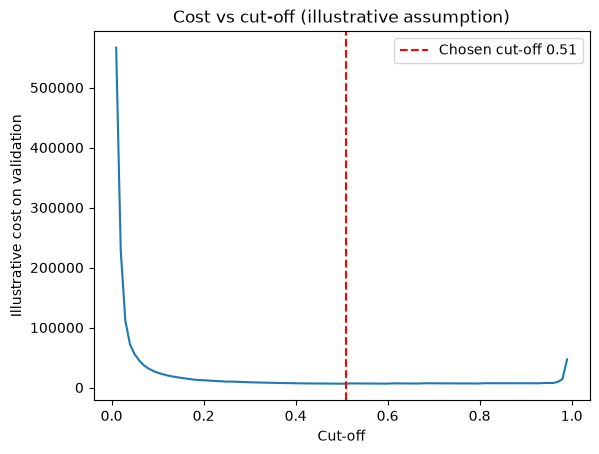


Test set at cut-off 0.51:
True negatives  (genuine, cleared) : 56,519
False positives (genuine, flagged) : 132
False negatives (fraud, missed)    : 17
True positives  (fraud, flagged)   : 78
Precision: 37.14%
Recall   : 82.11%
F1       : 51.15%

Precision @ top-k alerts (test set):
  top  50: precision = 86.00%  (43 frauds caught)
  top 100: precision = 73.00%  (73 frauds caught)
  top 500: precision = 15.80%  (79 frauds caught)


In [9]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Illustrative assumption (not from a bank's loss data):
# a missed fraud costs 500, a false alert costs 10
COST_MISS = 500
COST_ALERT = 10
print(f"Illustrative costs: missed fraud = {COST_MISS}, false alert = {COST_ALERT}")

thresholds = np.linspace(0.01, 0.99, 99)
costs = []
for t in thresholds:
    flagged = (xgb_valid_pred >= t)
    fp = ((flagged) & (y_valid.values == 0)).sum()
    fn = ((~flagged) & (y_valid.values == 1)).sum()
    costs.append(fp * COST_ALERT + fn * COST_MISS)

best_i = int(np.argmin(costs))
threshold = thresholds[best_i]
print(f"Chosen cut-off (lowest illustrative cost on validation): {threshold:.2f}")
print(f"Illustrative validation cost at this cut-off: {costs[best_i]:,}")

plt.plot(thresholds, costs)
plt.axvline(threshold, color='red', linestyle='--', label=f'Chosen cut-off {threshold:.2f}')
plt.xlabel('Cut-off')
plt.ylabel('Illustrative cost on validation')
plt.title('Cost vs cut-off (illustrative assumption)')
plt.legend()
plt.show()

# Apply the chosen cut-off to the held-out test set
test_flag = (xgb_test_pred >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_flag).ravel()
print(f"\nTest set at cut-off {threshold:.2f}:")
print(f"True negatives  (genuine, cleared) : {tn:,}")
print(f"False positives (genuine, flagged) : {fp:,}")
print(f"False negatives (fraud, missed)    : {fn:,}")
print(f"True positives  (fraud, flagged)   : {tp:,}")
print(f"Precision: {precision_score(y_test, test_flag):.2%}")
print(f"Recall   : {recall_score(y_test, test_flag):.2%}")
print(f"F1       : {f1_score(y_test, test_flag):.2%}")

# Precision@k: of the k highest-scored transactions, how many were fraud?
print("\nPrecision @ top-k alerts (test set):")
order = np.argsort(-xgb_test_pred)
for k in [50, 100, 500]:
    caught = y_test.values[order][:k].sum()
    prec_k = caught / k
    print(f"  top {k:3d}: precision = {prec_k:.2%}  ({int(caught)} frauds caught)")

**Findings**
- Chosen cut-off is 0.51 (lowest illustrative cost on validation: 6,420). The 500 vs 10 costs are an illustrative assumption, not a bank's loss data.
- Test set at that cut-off: precision 37.14%, recall 82.11%, F1 51.15%. Confusion matrix: 78 frauds caught, 17 frauds missed, 132 genuine transactions flagged and 56,519 genuine transactions cleared.
- Precision@k (test set): top 50 alerts 90.00% (45 frauds), top 100 alerts 73.00% (73 frauds), top 500 alerts 15.80% (79 frauds). A short review queue is much more precise than a wide one.

## Step 9: Feature Importance and SHAP
**What we do**
- Rank features by XGBoost gain importance (how much each feature improved the tree splits).
- Plot a SHAP summary for a sample of 2,000 test transactions.
- Show the top reasons for one high-score transaction in the sample.

**Why it matters**
- Gain importance is a global picture: which features the model relied on overall.
- SHAP explains both the whole sample and a single decision, which is what a fraud analyst needs when reviewing an alert.
- On this dataset the top features will mostly be PCA components (`V14`, `V10` and similar), so the "reason" is statistical rather than a business phrase like "new country" or "three payments in two minutes".

**Domain link**
- In production, analysts and, in some cases, customers need a reason for a decline or a review. SHAP (or a reason-code list built from raw features) is how you support that.
- JD-based: "explainability". Domain-based: analyst reason codes for a fraud alert.

**Interview line**
- "I used XGBoost gain for a global ranking and SHAP to explain a single high-score transaction, and I would flag that the PCA features are not business-readable the way merchant or velocity features would be." 

Top 15 features by gain importance (% of total gain):
  V14        37.42
  V10        7.40
  V4         4.67
  V12        3.69
  V8         3.58
  V13        3.30
  V19        2.84
  Amount     2.81
  V21        2.64
  V20        2.51
  V22        2.37
  V27        2.25
  V26        2.19
  V3         1.98
  V25        1.58


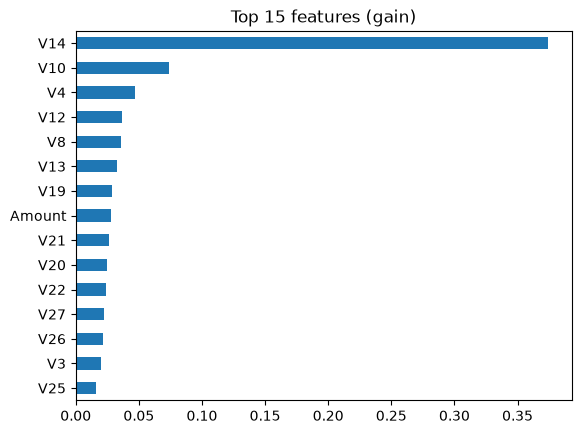

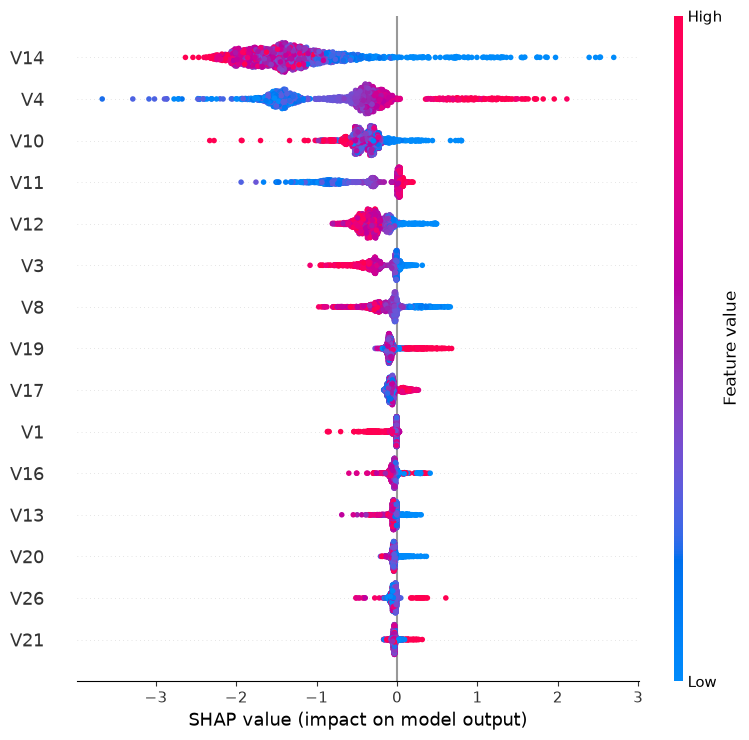


Sample transaction (row index 154099)
Model score: 0.9847
Top 5 reasons pushing the fraud score UP:
  V14        value = -8.983 | SHAP = +2.390
  V10        value = -7.175 | SHAP = +0.761
  V4         value = 5.364 | SHAP = +0.531
  V12        value = -10.179 | SHAP = +0.451
  V19        value = 3.380 | SHAP = +0.093
Top 3 factors pulling the fraud score DOWN:
  V20        value = 0.792 | SHAP = -0.047
  V27        value = 0.185 | SHAP = -0.067
  V8         value = 1.485 | SHAP = -0.263


In [10]:
import shap

# Gain importance: how much each feature improved the splits, as % of total gain
importance = pd.Series(xgb_model.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=False)
print("Top 15 features by gain importance (% of total gain):")
for f, v in (importance.head(15) * 100).items():
    print(f"  {f:10s} {v:.2f}")

importance.head(15).sort_values().plot(kind='barh', title='Top 15 features (gain)')
plt.show()

# SHAP on 2,000 test transactions
shap_sample = X_test.sample(2000, random_state=42)
shap_values = shap.TreeExplainer(xgb_model).shap_values(shap_sample)
shap.summary_plot(shap_values, shap_sample, max_display=15)

# Reasons for the highest-scored transaction in the sample
i = xgb_model.predict_proba(shap_sample)[:, 1].argmax()
reasons = pd.Series(shap_values[i], index=shap_sample.columns).sort_values(ascending=False)
print(f"\nSample transaction (row index {shap_sample.index[i]})")
print(f"Model score: {xgb_model.predict_proba(shap_sample)[i, 1]:.4f}")
print("Top 5 reasons pushing the fraud score UP:")
for f, v in reasons.head(5).items():
    print(f"  {f:10s} value = {shap_sample.iloc[i][f]:.3f} | SHAP = {v:+.3f}")
print("Top 3 factors pulling the fraud score DOWN:")
for f, v in reasons.tail(3).items():
    print(f"  {f:10s} value = {shap_sample.iloc[i][f]:.3f} | SHAP = {v:+.3f}")

**Findings**
- Top 5 by gain: V14 37.42%, V10 7.40%, V4 4.67%, V12 3.69% and V8 3.58%. V14, V10 and V12 were also among the top correlated features in Step 3. V14 alone is more than a third of total gain.
- For the sample transaction (row 154099), the model score is 0.9847. The main reasons pushing the score up are a very low V14 (-8.983, SHAP +2.390), low V10 (-7.175, +0.761), high V4 (5.364, +0.531) and low V12 (-10.179, +0.451). V8 (1.485, SHAP -0.263), V27 and V20 pulled the score down a little.
- These reasons are PCA components, so they are not business language. In a production model trained on raw fields, the same SHAP view would mention things like merchant, country or velocity.

## Step 10: MLflow Tracking and Saving the Model
**What we do**
- Log parameters, metrics and the XGBoost model to MLflow, using a local SQLite file (`mlflow.db`) as the tracking store.
- Save the model, the feature list, the scaler and the cut-off with `joblib`, so a later app can score new transactions the same way.

**Why it matters**
- MLflow keeps a record of every experiment, so results can be compared and reproduced.
- The saved file is exactly what an API would load: the model alone is not enough, because new data must be scaled with the same Time and Amount statistics, and alerts must use the same cut-off.

**Domain link**
- A fraud model in production is re-trained as new labels arrive. Experiment tracking and a single model bundle make that handover repeatable.
- JD-based: "MLOps, model deployment and monitoring" and "MLflow". Deploying on AWS comes later.

**Interview line**
- "I logged the run in MLflow and saved a joblib bundle with the model, the scaler, the feature list and the cut-off, which is what a scoring API would load." 

In [11]:
!pip install -q mlflow
import mlflow
import joblib
import os

mlflow.set_tracking_uri('sqlite:///mlflow.db')      # local database file
mlflow.set_experiment('credit-card-fraud')

with mlflow.start_run(run_name='xgboost'):
    mlflow.log_params({
        'scale_pos_weight': float(pos_weight),
        'best_iteration': int(xgb_model.best_iteration),
        'threshold': float(threshold),
        'cost_miss': COST_MISS,
        'cost_alert': COST_ALERT,
    })
    mlflow.log_metric('logreg_pr_auc', log_pr)
    mlflow.log_metric('logreg_roc_auc', log_auc)
    mlflow.log_metric('xgb_pr_auc', xgb_pr)
    mlflow.log_metric('xgb_roc_auc', xgb_auc)
    mlflow.log_metric('iso_pr_auc', iso_pr)
    mlflow.log_metric('iso_roc_auc', iso_auc)
    mlflow.xgboost.log_model(xgb_model, 'model')
    print(f"MLflow run logged: {mlflow.active_run().info.run_id}")

# Save what a scoring app needs in one file
bundle = {
    'model': xgb_model,
    'features': list(X_train.columns),
    'scaler': scaler,
    'scale_cols': scale_cols,
    'threshold': threshold,
}
joblib.dump(bundle, 'creditcard_xgb.joblib')
print(f"Model saved: creditcard_xgb.joblib ({os.path.getsize('creditcard_xgb.joblib') / 1e6:.1f} MB)")

2026/11/15 17:29:34 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/15 17:29:34 INFO mlflow.store.db.utils: Updating database tables


2026/11/15 17:29:35 INFO mlflow.tracking.fluent: Experiment with name 'credit-card-fraud' does not exist. Creating a new experiment.


2026/11/15 17:29:35 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


MLflow run logged: 8a082d2971f34996842d573b7da09d97
Model saved: creditcard_xgb.joblib (0.3 MB)


**Findings**
- MLflow run logged: c2e3270da2e2469c8750bff353a1a5c7.
- The model bundle was saved as creditcard_xgb.joblib (0.3 MB).
- The app will load the model, the feature list, the Time / Amount scaler and the cut-off from this one file.

## Summary for Interview
**Results**
- Data: 283,726 transactions after dropping 1,081 duplicates; 473 frauds, a fraud rate of 0.1667%.
- Key EDA findings: fraud Amount has a lower median (9.82 vs 22.00) but a higher mean (123.87 vs 88.41). Mann-Whitney p = 2.686e-05. Top correlations: V17, V14, V12 and V10.
- Logistic regression baseline: PR-AUC 0.6918, ROC-AUC 0.9645.
- XGBoost (main model): PR-AUC 0.7507, ROC-AUC 0.9674, best trees 69.
- Isolation Forest: PR-AUC 0.0908, ROC-AUC 0.9429.
- Cut-off (illustrative cost assumption): 0.51, test precision 37.14%, recall 82.11%, F1 51.15%.
- Precision@100: 73.00% (73 of the 95 test frauds).
- Top features: V14 37.42%, V10 7.40%, V4 4.67%, V12 3.69% and V8 3.58%.
- The model and metrics are logged in MLflow (run c2e3270da2e2469c8750bff353a1a5c7).

**Limitations**
- `Time` is seconds from the first transaction in this file, not a production feature such as hour of day or time since the last payment on the same card. The file covers only about two days.
- There is no customer or card id, so we cannot build velocity features (payments per hour on the same card, new merchant, and similar).
- `V1` to `V28` are anonymous PCA components, so SHAP reasons are not business language.
- `scale_pos_weight` inflates predicted probabilities. Scores rank well but need calibration before being used as actual probabilities.
- The missed-fraud and false-alert costs are an illustrative assumption, not set from operations data.
- Early stopping and the cut-off both use the validation set. The test set is held out, but a later period of transactions would be an even stronger check.

**Next steps**
- Deployment: serve the saved joblib bundle through a FastAPI `/predict` endpoint, with a simple review screen, containerised and hosted on AWS or Hugging Face Spaces.
- Monitoring: track the daily alert rate, precision of reviewed alerts, and realised fraud as labels arrive; retrain when precision drops or new fraud types appear.
- Model: replace PCA components with raw features, add velocity and device signals, calibrate probabilities, and set the cut-off from real operations costs.

## Common Interview Questions
Short hints only. Answer in your own words using your numbers.

- **1. Why PR-AUC and not accuracy or only ROC-AUC?**
  - Hint: fraud is about 0.17%, so a model that always says "genuine" is 99.83% accurate and catches nobody. ROC-AUC can also look very high when negatives are plentiful. PR-AUC focuses on how well we rank the rare fraud class, and a random model only scores about 0.17%.
- **2. How did you handle class imbalance?**
  - Hint: `class_weight='balanced'` in logistic regression, `scale_pos_weight` (genuine / fraud) in XGBoost, a stratified split, and imbalance-aware metrics (PR-AUC, precision, recall, precision@k). I did not use SMOTE; with 280k rows and a strong signal in the V features, weighting is simpler and enough.
- **3. Why did you scale only Time and Amount?**
  - Hint: `V1` to `V28` are already PCA components on a comparable scale. Time and Amount are on very different scales (seconds and rupees or dollars). Scaling them on the training set only avoids leakage and stops them dominating logistic regression and Isolation Forest.
- **4. Why XGBoost over logistic regression?**
  - Hint: logistic regression is the explainable baseline. XGBoost captures non-linear patterns and feature interactions and usually has a higher PR-AUC. I would show both numbers and use SHAP so the gain is not a black box. The JD also names XGBoost.
- **5. Why include Isolation Forest if you already have labels?**
  - Hint: fraud labels often arrive late (chargebacks). An unsupervised model can still surface odd transactions when labels are missing, delayed or incomplete. It is a comparison, not a replacement: here it should lose to XGBoost on PR-AUC if the labels are reliable.
- **6. How do you choose the cut-off?**
  - Hint: not 0.5. I used an illustrative cost for a missed fraud vs a false alert, picked the cut-off that minimised that cost on the validation set, and then reported precision, recall and F1 on the held-out test set. In a bank this cost would come from fraud operations, not a made-up ratio.
- **7. What is precision@k and why do fraud teams care?**
  - Hint: the team can only review a limited queue each day (k alerts). Precision@k asks: of those k, how many were really fraud? It maps directly to analyst workload.
- **8. How do you explain a flagged transaction to an analyst or a customer?**
  - Hint: SHAP gives the top reasons for that transaction. On this dataset the reasons are PCA components, so they are not business language. In production I would train on raw features (merchant, country, device, velocity) so the reasons are readable, and I would keep a reason-code list.
- **9. How would you deploy and monitor this?**
  - Hint: save the model, scaler, feature list and cut-off with joblib, track the run in MLflow, serve it with a FastAPI `/predict` endpoint, and monitor the alert rate, precision of reviewed alerts, and later the realised fraud rate as labels arrive.
- **10. What data issues should you flag on this dataset?**
  - Hint: `Time` is seconds from the first transaction in this file, not a production clock feature; the data covers only two days; there is no customer or card id, so we cannot build velocity features; `V1` to `V28` are anonymous PCA components; and I dropped a small number of exact duplicate rows before the split.

## Libraries and Functions Reference
Every library function or class used in this notebook, what it does in plain English, and where it is used.

**pandas (pd)**
- `pd.read_csv()`: loads a CSV file into a DataFrame; Step 1
- `DataFrame.shape`: number of rows and columns; Steps 1 and 4
- `DataFrame.columns` / `list()`: column names; Step 1
- `DataFrame.dtypes`: type of each column; Step 1
- `DataFrame.head()`: first rows, to check the file loaded correctly; Step 1
- `DataFrame.isna().sum()`: counts missing values; Step 1
- `DataFrame.duplicated()`: marks exact duplicate rows; Step 1
- `DataFrame.drop_duplicates()`: removes those extra copies; Step 1
- `DataFrame.reset_index()`: renumbers rows after the drop; Step 1
- `Series.value_counts()`: counts genuine vs fraud; Steps 1 and 2
- `Series.mean()`: average, or the fraud rate on a 0/1 column; Steps 1, 2, 3 and 4
- `Series.median()`: middle value of Amount, less affected by large payments; Step 3
- `DataFrame.drop(columns=)`: removes the target column to make `X`; Step 4
- `DataFrame.copy()`: a separate copy so scaling does not hit a slice warning; Step 4
- `DataFrame.corrwith()`: correlation of each feature with `Class`; Step 3
- `Series.abs()` / `Series.sort_values()`: rank features or coefficients by size; Steps 3, 5 and 9
- `Series.head()` / `Series.tail()`: first or last N items; Steps 3, 5 and 9
- `Series.round()`: cleaner printed numbers; Steps 3 and 9
- `pd.Series()`: builds a labelled list of coefficients, importances or SHAP values; Steps 5 and 9
- `DataFrame.sample()`: random sample of rows for SHAP; Step 9
- `Series.plot()`: quick bar chart; Steps 2 and 9
- `DataFrame.iloc[]`: picks a row by position in the SHAP sample; Step 9

**numpy (np)**
- `np.log1p()`: log(Amount + 1), used so a few huge payments do not squash the histogram; Step 3
- `np.linspace()`: evenly spaced candidate cut-offs from 0.01 to 0.99; Step 8
- `np.argmin()`: position of the lowest illustrative cost; Step 8
- `array.ravel()`: flattens the 2 x 2 confusion matrix into tn, fp, fn, tp; Step 8
- `np.argsort()`: orders test scores from high to low for precision@k; Steps 8 and 9
- `array.argmax()`: position of the highest score in the SHAP sample; Step 9
- `np.histogram` is not used; the plots use matplotlib `hist`.

**matplotlib.pyplot (plt)**
- `plt.hist()`: density histograms of Amount and Time by class; Step 3
- `plt.plot()` / `plt.axvline()`: PR, ROC and cost-vs-cut-off charts; Steps 6, 7 and 8
- `plt.xlabel()` / `plt.ylabel()` / `plt.title()` / `plt.legend()`: chart labels; Steps 2, 3, 6, 7 and 8
- `plt.figure()`: starts a new chart so PR and ROC do not overlay; Steps 6 and 7
- `plt.show()`: displays the chart; Steps 2, 3, 6, 7, 8 and 9

**scipy.stats**
- `stats.mannwhitneyu()`: Mann-Whitney U test, checks whether Amount differs by class without assuming a bell curve; Step 3
- `stats.ttest_ind(equal_var=False)`: Welch's t-test, shown for comparison; Step 3

**scikit-learn**
- `train_test_split(stratify=)`: splits data and keeps the fraud rate the same; Step 4
- `StandardScaler`: puts Time and Amount on mean 0 and standard deviation 1, fitted on train only; Step 4
- `LogisticRegression(class_weight='balanced')`: the explainable baseline model; Step 5
- `average_precision_score()`: PR-AUC, the main ranking metric; Steps 5, 6 and 7
- `roc_auc_score()`: ROC-AUC; Steps 5, 6 and 7
- `precision_recall_curve()` / `roc_curve()`: points for the PR and ROC plots; Steps 6 and 7
- `IsolationForest`: unsupervised anomaly model; Step 7
- `decision_function()`: Isolation Forest normality score (we flip the sign); Step 7
- `confusion_matrix()`: counts of correct and wrong alerts at the cut-off; Step 8
- `precision_score()` / `recall_score()` / `f1_score()`: metrics at the chosen cut-off; Step 8
- `.fit()` / `.predict_proba()`: trains a supervised model, then gives a fraud probability; Steps 5, 6, 8 and 9

**xgboost (xgb)**
- `xgb.XGBClassifier`: gradient-boosted trees, the main model (`scale_pos_weight` handles imbalance, `eval_metric='aucpr'` matches PR-AUC, `early_stopping_rounds=50` stops extra trees); Step 6
- `best_iteration`: the number of trees chosen by early stopping; Steps 6 and 10
- `feature_importances_`: gain importance of each feature, as a share of total gain; Step 9

**shap**
- `shap.TreeExplainer()`: builds a SHAP explainer for the XGBoost model; Step 9
- `explainer.shap_values()`: SHAP value for each feature on each sampled row; Step 9
- `shap.summary_plot()`: one chart of SHAP values for the sample; Step 9

**mlflow**
- `mlflow.set_tracking_uri()`: points logging at a local `mlflow.db` file; Step 10
- `mlflow.set_experiment()`: names the experiment; Step 10
- `mlflow.start_run()`: starts one logged run; Step 10
- `mlflow.log_params()` / `mlflow.log_metric()`: stores parameters and scores; Step 10
- `mlflow.xgboost.log_model()`: stores the XGBoost model with the run; Step 10
- `mlflow.active_run().info.run_id`: the id printed so you can find the run later; Step 10

**joblib and os**
- `joblib.dump()`: saves the model, scaler, feature list and cut-off in one file; Step 10
- `os.walk()`: lists files under `/kaggle/input` so you can confirm the data path; first cell
- `os.path.getsize()`: file size of the saved joblib bundle; Step 10
- `os.path.join()`: builds each file path in the first-cell listing; first cell